# Variogramme sur une scène réelle : orthophotographie de Toulouse

Exemple sur données réelles (voir `PLAN_TESTS_DONNEES_REELLES.md`) : il
montre l'usage de `variogram_noise` et ses contrôles, il ne valide pas la
méthode (validation sur simulation : `docs/technique/bruit-variogramme.md`).

**Données** : extrait de 10240 × 10240 pixels (5 cm, RGB 8 bits, place du
Capitole) de l'*Orthophotoplan 2024* de Toulouse Métropole, Licence
Ouverte v2.0 (Etalab), téléchargé hors du projet (voir la référence
technique d'eoqual-resampling, §8, pour l'emprise). Rien n'est copié ni
versionné ; la figure produite ne contient que des courbes.

## 1. Configuration

In [1]:
from pathlib import Path

import numpy as np
import tifffile
import matplotlib.pyplot as plt

import eoqual.measure as em
from eoqual.measure.noise import variogram, variogram_noise

IMAGE = Path("../../../IMAGES/capitole_10240.tif")   # hors du dépôt, à adapter
FIGURE = Path("../docs/technique/figures/variogram_orthophoto.png")
ZONE = 256      # côté des zones analysées (pixels de 5 cm : 12,8 m)
print("eoqual-measure", em.__version__)

eoqual-measure 0.4.0


## 2. Lecture et contrôles des données

In [2]:
rgb = tifffile.imread(IMAGE)
Y = 0.299 * rgb[..., 0] + 0.587 * rgb[..., 1] + 0.114 * rgb[..., 2]
print(rgb.shape, rgb.dtype, "| codes min/max :", rgb.min(), rgb.max(),
      "| pixels saturés (255) :", f"{np.mean(rgb == 255):.2%}")

(10240, 10240, 3) uint8 | codes min/max : 0 255 | pixels saturés (255) : 0.02%


## 3. Zones analysées

La zone la plus lisse (énergie de gradient) dans trois gammes de
luminance, sans pixel saturé, plus une zone texturée (90e centile).

In [3]:
n = Y.shape[0] // ZONE
blocks = []
for i in range(n):
    for j in range(n):
        b = Y[i * ZONE:(i + 1) * ZONE, j * ZONE:(j + 1) * ZONE]
        gy, gx = np.gradient(b)
        blocks.append(dict(i=i, j=j, grad=float(np.mean(gx**2 + gy**2)), mean=float(b.mean()),
                           sat=float(np.mean(b >= 250) + np.mean(b <= 3))))
ok = [b for b in blocks if b["sat"] < 1e-3]
zones = {}
for label, lo, hi in (("lisse, sombre", 30, 90), ("lisse, moyenne", 90, 150), ("lisse, claire", 150, 230)):
    zones[label] = min((b for b in ok if lo <= b["mean"] < hi), key=lambda b: b["grad"])
zones["texturée"] = sorted(ok, key=lambda b: b["grad"])[int(0.9 * len(ok))]
for k, z in zones.items():
    print(f"{k:15s} bloc ({z['i']}, {z['j']}) luminance {z['mean']:.0f}")

lisse, sombre   bloc (12, 22) luminance 85
lisse, moyenne  bloc (25, 31) luminance 128
lisse, claire   bloc (19, 13) luminance 180
texturée        bloc (8, 33) luminance 140


## 4. Mesures

Toutes les tuiles de chaque zone sont gardées (`keep_fraction=1`) : la zone
a déjà été choisie lisse.

In [4]:
patch = lambda z: Y[z["i"] * ZONE:(z["i"] + 1) * ZONE, z["j"] * ZONE:(z["j"] + 1) * ZONE]
rows = []
for k, z in zones.items():
    r = variogram_noise(patch(z), keep_fraction=1.0)
    p = em.estimate_noise(patch(z), "ponomarenko")
    rows.append((k, z["mean"], r, float(np.ravel(p.variance)[0])))
    print(f"{k:15s} σ² = {r.variance:6.2f} ± {r.u_variance:.2f}  F = {r.nugget_fraction:5.2f}  "
          f"anisotropie {r.anisotropy:+6.1f} u  fiable : {r.reliable}  | Ponomarenko σ² = {rows[-1][3]:.2f}")
g = variogram_noise(Y, saturation=250)
print(f"\nImage entière (50 % des tuiles les plus lisses) : σ² = {g.variance:.2f} ± {g.u_variance:.2f}, "
      f"F = {g.nugget_fraction:.2f}, fiable : {g.reliable}")

lisse, sombre   σ² =  -7.03 ± 1.43  F = -0.77  anisotropie   +2.0 u  fiable : False  | Ponomarenko σ² = 0.24
lisse, moyenne  σ² =  -2.97 ± 0.89  F = -0.89  anisotropie   -0.2 u  fiable : False  | Ponomarenko σ² = 0.12
lisse, claire   σ² =  -0.75 ± 0.03  F = -0.51  anisotropie   +2.1 u  fiable : False  | Ponomarenko σ² = 0.11
texturée        σ² = -38.10 ± 2.35  F = -0.66  anisotropie   +3.7 u  fiable : False  | Ponomarenko σ² = 0.76



Image entière (50 % des tuiles les plus lisses) : σ² = -7.74 ± 0.03, F = -0.43, fiable : False


## 5. Contrôle : bruit blanc connu ajouté à une zone réelle

Si la méthode fonctionne, un bruit blanc ajouté doit augmenter la pépite
exactement de sa variance, même quand la pépite de la zone seule est
négative (scène lissée).'''

In [5]:
base = patch(zones["lisse, moyenne"])
rng = np.random.default_rng(0)
control = []
for s in (0.0, 1.0, 2.0, 4.0):
    r = variogram_noise(base + rng.normal(0.0, s, base.shape) if s else base, keep_fraction=1.0)
    control.append((s, r))
    gain = r.variance - control[0][1].variance
    print(f"bruit ajouté σ = {s}: pépite {r.variance:6.2f}, écart à la zone seule {gain:6.2f} "
          f"(attendu {s*s:g}), F = {r.nugget_fraction:.2f}, fiable : {r.reliable}")

bruit ajouté σ = 0.0: pépite  -2.97, écart à la zone seule   0.00 (attendu 0), F = -0.89, fiable : False
bruit ajouté σ = 1.0: pépite  -1.97, écart à la zone seule   1.01 (attendu 1), F = -0.45, fiable : False
bruit ajouté σ = 2.0: pépite   1.08, écart à la zone seule   4.05 (attendu 4), F = 0.15, fiable : False
bruit ajouté σ = 4.0: pépite  13.19, écart à la zone seule  16.16 (attendu 16), F = 0.68, fiable : False


## 6. Figure (courbes seulement)

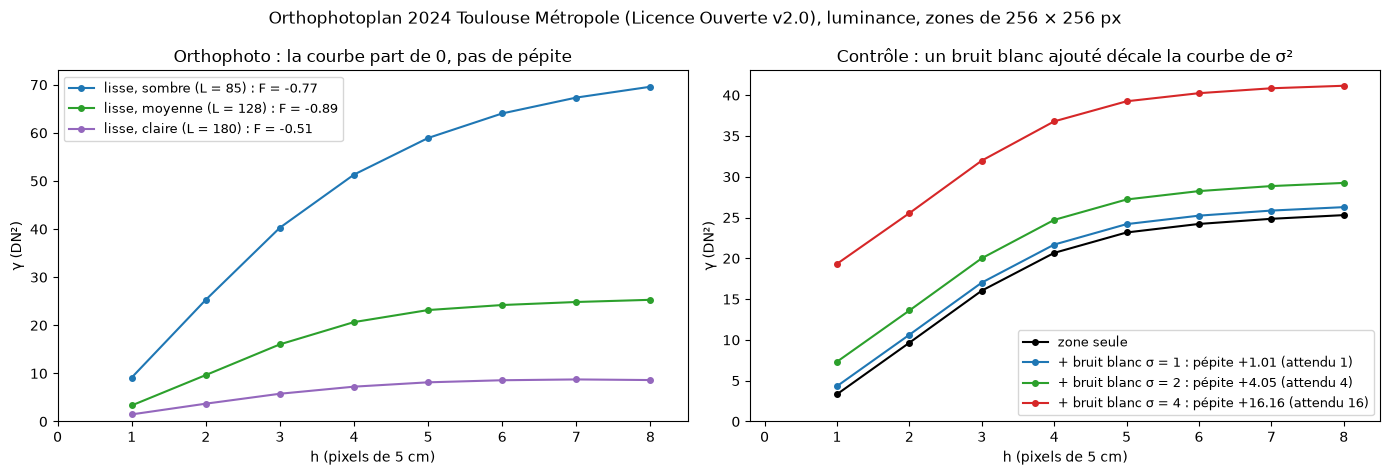

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for (k, mean, r, pono), col in zip(rows[:3], ("tab:blue", "tab:green", "tab:purple")):
    v = variogram(patch(zones[k]), max_lag=8, keep_fraction=1.0)
    ax[0].plot(v.lags, v.gamma, "o-", ms=4, color=col, label=f"{k} (L = {mean:.0f}) : F = {r.nugget_fraction:.2f}")
ax[0].set(xlim=(0, 8.5), ylim=(0, None), xlabel="h (pixels de 5 cm)", ylabel="γ (DN²)",
          title="Orthophoto : la courbe part de 0, pas de pépite")
ax[0].legend(fontsize=9)
for (s, r), col in zip(control, ("k", "tab:blue", "tab:green", "tab:red")):
    v = variogram(base + np.random.default_rng(0).normal(0.0, s, base.shape) if s else base,
                  max_lag=8, keep_fraction=1.0)
    lab = "zone seule" if s == 0 else f"+ bruit blanc σ = {s:g}"
    gain = r.variance - control[0][1].variance
    ax[1].plot(v.lags, v.gamma, "o-", ms=4, color=col,
               label=lab if s == 0 else f"{lab} : pépite +{gain:.2f} (attendu {s*s:g})")
ax[1].set(xlim=(-0.2, 8.5), ylim=(0, None), xlabel="h (pixels de 5 cm)", ylabel="γ (DN²)",
          title="Contrôle : un bruit blanc ajouté décale la courbe de σ²")
ax[1].legend(fontsize=9)
fig.suptitle("Orthophotoplan 2024 Toulouse Métropole (Licence Ouverte v2.0), luminance, zones de 256 × 256 px")
fig.tight_layout()
fig.savefig(FIGURE, dpi=120)

## 7. Conclusion

- Aucune pépite sur les zones lisses : le bruit de l'orthophoto n'est pas
  blanc. Le produit a été dématricé, orthorectifié (rééchantillonné),
  mosaïqué et probablement débruité ou compressé : chaque étape corrèle le
  bruit entre voisins. `reliable` vaut `False`, à juste titre.
- Le contrôle montre que la méthode retrouve un bruit blanc ajouté (la
  pépite augmente exactement de σ²) : c'est l'image, pas la méthode, qui
  n'a pas de bruit blanc mesurable. Comme la courbe de la zone seule part
  sous zéro (scène lissée), la pépite absolue n'est juste que pour un bruit
  bien plus fort que ce décalage (F reste < 0,8 jusqu'à σ = 4).
- Ponomarenko trouve quelques dixièmes de DN² ; il suppose lui aussi un
  bruit blanc, sans le vérifier : sa valeur est à prendre comme une borne
  basse, pas comme le bruit du capteur.
- Pour mesurer le bruit du capteur, il faut les images brutes de
  l'acquisition aérienne, pas l'orthophoto.